# Case Study 1: Titanic Survival Prediction using Logistic Regression
### Course: Foundations of Data Science (FDS)
**Student Name:** [Your Name] &nbsp;|&nbsp; **Roll Number:** [Your Roll No] &nbsp;|&nbsp; **Section:** [Your Section] &nbsp;|&nbsp; **Semester:** Fall 2026

---

### Project Overview & Objectives
In this case study, I am building a **Logistic Regression** model from scratch using `scikit-learn` to predict whether a passenger survived the Titanic sinking.

Here is my step-by-step roadmap:
1. **Exploratory Data Analysis (EDA):** Inspect distributions, summary statistics, missing values, and visualize demographic trends.
2. **Data Preprocessing & Cleaning:** Handle missing data logically, encode categorical columns, and scale features.
3. **Model Training:** Build a clean `Pipeline` with `ColumnTransformer` and fit a `LogisticRegression` classifier.
4. **Evaluation:** Measure performance using Accuracy, Precision, Recall, F1-score, and ROC-AUC curve.
5. **Interpretation:** Calculate Odds Ratios ($e^\beta$) to explain which features had the biggest impact on survival.
6. **Web Deployment:** Deploy the model into an interactive Streamlit application (`app.py`).

## Step 1: Importing Libraries and Loading Data
First, I will import all standard data science packages (`pandas`, `numpy`, `matplotlib`, `seaborn`) and load the provided `titanic.csv` dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Styling for clean, readable plots
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 10

# Load dataset
df = pd.read_csv('titanic.csv')
print(f"Dataset loaded successfully! Total rows: {df.shape[0]}, Total columns: {df.shape[1]}")
df.head()

Dataset loaded successfully! Total rows: 891, Total columns: 12


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Step 2: Data Inspection & Missing Values Check
Let's inspect the data types, non-null counts, and identify which columns have missing values that need cleaning.

In [2]:
# Basic information about columns and types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [3]:
# Summary of missing values in each column
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_table = pd.DataFrame({'Missing Values': missing, 'Percentage (%)': missing_pct})
missing_table[missing_table['Missing Values'] > 0]

,Missing Values,Percentage (%)
Age,177,19.865320
Cabin,687,77.104377
Embarked,2,0.224467


**Student Observations on Missing Data:**
- `Age`: Missing in 177 rows (~19.9%). Since age is an important predictor for survival (children first), I should impute this carefully rather than dropping it.
- `Cabin`: Missing in 687 rows (~77.1%). This is way too sparse, so it makes sense to drop it.
- `Embarked`: Missing in only 2 rows (~0.2%). I can easily fill these two with the most common port (mode).

In [4]:
# Numerical features summary statistics
print("Numerical Features Summary:")
df.describe().round(2)

Numerical Features Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


In [5]:
# Categorical features summary statistics
print("Categorical Features Summary:")
df.describe(include=['object', 'str'])

Categorical Features Summary:


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


## Step 3: Exploratory Data Analysis (EDA) & Visualizations
Now, let's explore patterns in the data using visualizations to see how different passenger features relate to survival.

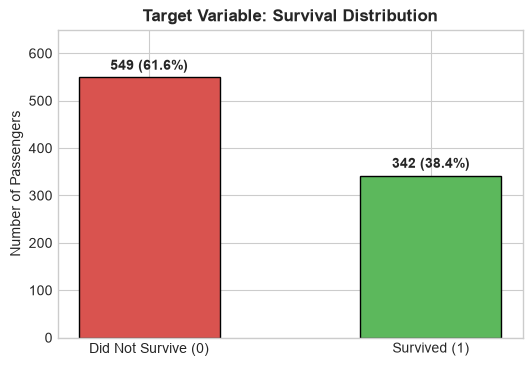

In [6]:
# 1. Target Variable: Overall Survival Count
survived_counts = df['Survived'].value_counts()
plt.figure(figsize=(6, 4))
bars = plt.bar(['Did Not Survive (0)', 'Survived (1)'], survived_counts.values, 
               color=['#d9534f', '#5cb85c'], edgecolor='black', width=0.5)

for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 10, f"{h} ({h/len(df)*100:.1f}%)", 
             ha='center', va='bottom', fontweight='bold')

plt.title('Target Variable: Survival Distribution', fontsize=12, fontweight='bold')
plt.ylabel('Number of Passengers')
plt.ylim(0, 650)
plt.show()

**Observation:** Out of 891 passengers, 549 (61.6%) perished and 342 (38.4%) survived. There is moderate class imbalance.

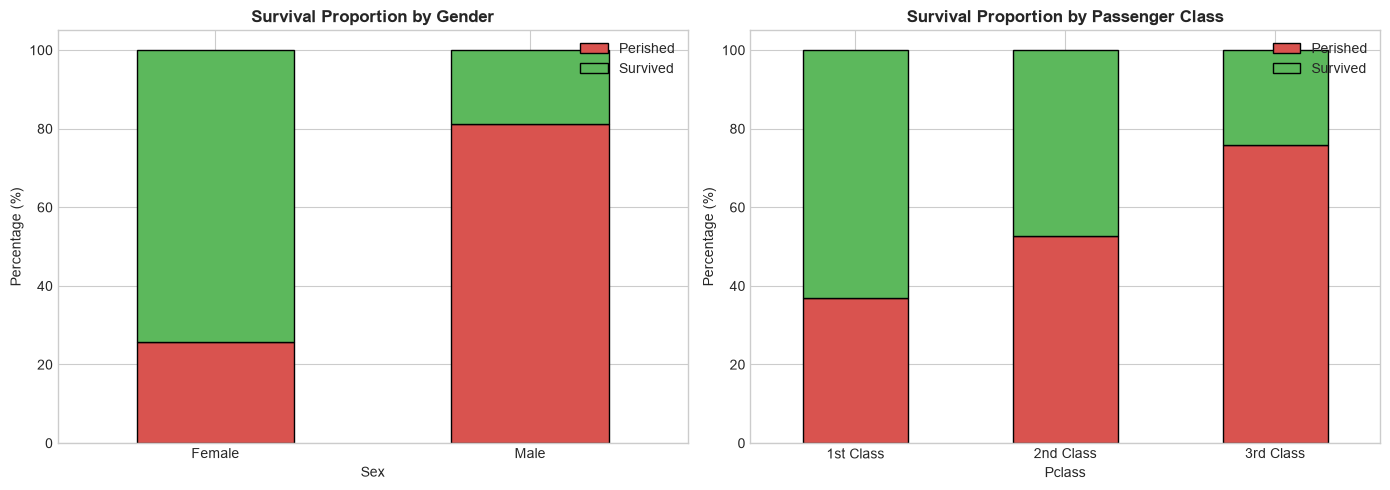

In [7]:
# 2. Survival by Gender & Class
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gender vs Survival
gender_pct = df.groupby('Sex')['Survived'].value_counts(normalize=True).unstack() * 100
gender_pct.plot(kind='bar', stacked=True, ax=axes[0], color=['#d9534f', '#5cb85c'], edgecolor='black', width=0.5)
axes[0].set_title('Survival Proportion by Gender', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Percentage (%)')
axes[0].set_xticklabels(['Female', 'Male'], rotation=0)
axes[0].legend(['Perished', 'Survived'], loc='upper right')

# Class vs Survival
class_pct = df.groupby('Pclass')['Survived'].value_counts(normalize=True).unstack() * 100
class_pct.plot(kind='bar', stacked=True, ax=axes[1], color=['#d9534f', '#5cb85c'], edgecolor='black', width=0.5)
axes[1].set_title('Survival Proportion by Passenger Class', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xticks([0, 1, 2])
axes[1].set_xticklabels(['1st Class', '2nd Class', '3rd Class'], rotation=0)
axes[1].legend(['Perished', 'Survived'], loc='upper right')

plt.tight_layout()
plt.show()

**Observations on Gender and Class:**
- **Gender is clearly the most decisive factor:** Over 74% of females survived, while only ~18.9% of males survived. This confirms the historical rule of *'women and children first'*.
- **Class privilege was massive:** 1st Class passengers had a 63% survival rate, 2nd Class had 47.3%, and 3rd Class had only 24.2%. 3rd class passengers were housed deep in the lower decks and had harder access to the lifeboats.

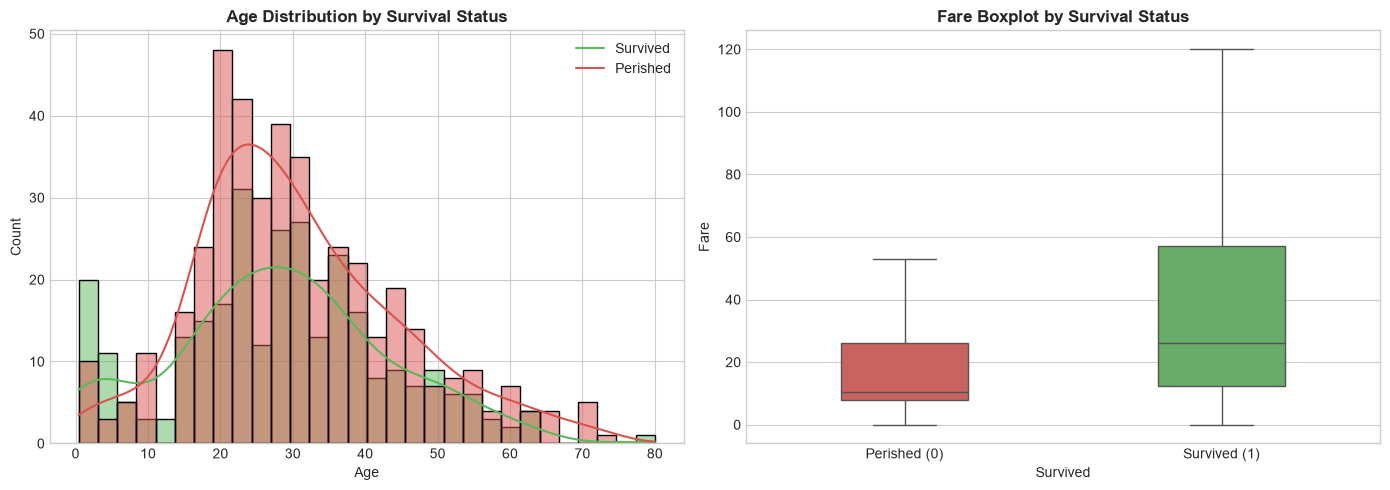

In [8]:
# 3. Age and Fare Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age Histogram with KDE
sns.histplot(data=df, x='Age', hue='Survived', kde=True, ax=axes[0], palette=['#d9534f', '#5cb85c'], bins=30)
axes[0].set_title('Age Distribution by Survival Status', fontsize=12, fontweight='bold')
axes[0].legend(['Survived', 'Perished'])

# Fare Boxplot (Suppressing extreme outliers for visual clarity)
sns.boxplot(data=df, x='Survived', y='Fare', hue='Survived', ax=axes[1], palette=['#d9534f', '#5cb85c'], width=0.4, showfliers=False, legend=False)
axes[1].set_title('Fare Boxplot by Survival Status', fontsize=12, fontweight='bold')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Perished (0)', 'Survived (1)'])

plt.tight_layout()
plt.show()

**Observations on Age and Fare:**
- Children under 10 had visibly higher survival rates.
- The median fare for survivors ($26.00) was more than double that of non-survivors ($10.50).

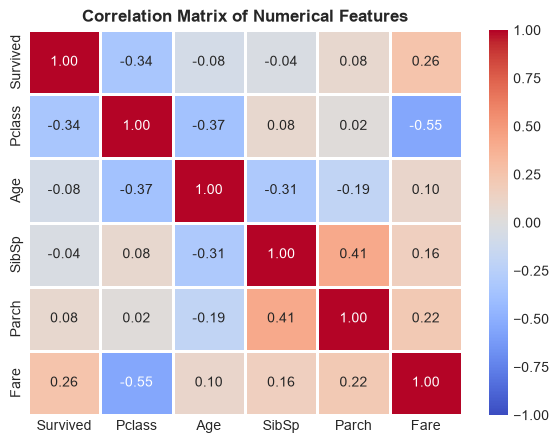

In [9]:
# 4. Correlation Heatmap
plt.figure(figsize=(7, 5))
numeric_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, linewidths=1)
plt.title('Correlation Matrix of Numerical Features', fontsize=12, fontweight='bold')
plt.show()

## Step 4: Data Preprocessing & Feature Engineering

### My Preprocessing Strategy:
1. **Conditional Imputation for Age:** Instead of using the overall mean (which is inaccurate because 1st class passengers are older than 3rd class), I computed the **median age grouped by `Pclass` and `Sex`**.
2. **Mode Imputation for Embarked:** Replaced the 2 missing ports with the most frequent port (`'S'`).
3. **Feature Selection:** Dropped `PassengerId`, `Name`, `Ticket` (unique text identifiers) and `Cabin` (>77% missing).
4. **Train/Test Split:** Used an 80/20 stratified split (`stratify=y`) so that the ratio of survivors to non-survivors remains consistent in both splits.
5. **One-Hot Encoding & Scaling:** Scaled numeric features (`Age`, `Fare`, `SibSp`, `Parch`) with `StandardScaler` and encoded categoricals (`Pclass`, `Sex`, `Embarked`) with `OneHotEncoder(drop='first')` to prevent the dummy variable trap.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Conditional Median Imputation for Age
age_medians = df.groupby(['Pclass', 'Sex'])['Age'].median()
df['Age'] = df.apply(lambda r: age_medians[r['Pclass'], r['Sex']] if pd.isnull(r['Age']) else r['Age'], axis=1)

# Mode imputation for Embarked and median safeguard for Fare
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Fare'] = df['Fare'].fillna(df['Fare'].median())

# Select final features and target
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
X = df[features]
y = df['Survived']

# 80% Train, 20% Test stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set samples: {X_train.shape[0]}")
print(f"Testing set samples:  {X_test.shape[0]}")

Training set samples: 712
Testing set samples:  179


## Step 5: Building and Training the Logistic Regression Model
I will use a `Pipeline` that combines the `ColumnTransformer` (for scaling and one-hot encoding) and the `LogisticRegression` model. This ensures clean code and prevents data leakage.

In [11]:
numeric_features = ['Age', 'Fare', 'SibSp', 'Parch']
categorical_features = ['Pclass', 'Sex', 'Embarked']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_features)
    ]
)

model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000, solver='lbfgs'))
])

# Train the model
model_pipeline.fit(X_train, y_train)
print("Logistic Regression model successfully trained on X_train!")

Logistic Regression model successfully trained on X_train!


## Step 6: Model Evaluation on Unseen Test Set
Now, I evaluate how well the model predicts on the 20% test data (`X_test`) using standard classification metrics:
- **Accuracy:** What fraction of overall predictions were correct?
- **Precision:** When the model predicts someone survived, how often is it right?
- **Recall:** Out of all people who actually survived, how many did the model find?
- **F1-Score:** The harmonic mean between precision and recall.
- **ROC-AUC Score:** The area under the ROC curve measuring ranking ability.

In [12]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

y_pred = model_pipeline.predict(X_test)
y_pred_proba = model_pipeline.predict_proba(X_test)[:, 1]

print("=" * 50)
print("TEST SET PERFORMANCE METRICS (N = 179)")
print("=" * 50)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f} ({accuracy_score(y_test, y_pred)*100:.2f}%)")
print(f"Precision: {precision_score(y_test, y_pred):.4f} ({precision_score(y_test, y_pred)*100:.2f}%)")
print(f"Recall:    {recall_score(y_test, y_pred):.4f} ({recall_score(y_test, y_pred)*100:.2f}%)")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f} ({f1_score(y_test, y_pred)*100:.2f}%)")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_pred_proba):.4f} ({roc_auc_score(y_test, y_pred_proba)*100:.2f}%)")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Did Not Survive (0)', 'Survived (1)']))

TEST SET PERFORMANCE METRICS (N = 179)
Accuracy:  0.8045 (80.45%)
Precision: 0.7931 (79.31%)
Recall:    0.6667 (66.67%)
F1-Score:  0.7244 (72.44%)
ROC-AUC:   0.8419 (84.19%)

Classification Report:
                     precision    recall  f1-score   support

Did Not Survive (0)       0.81      0.89      0.85       110
       Survived (1)       0.79      0.67      0.72        69

           accuracy                           0.80       179
          macro avg       0.80      0.78      0.79       179
       weighted avg       0.80      0.80      0.80       179



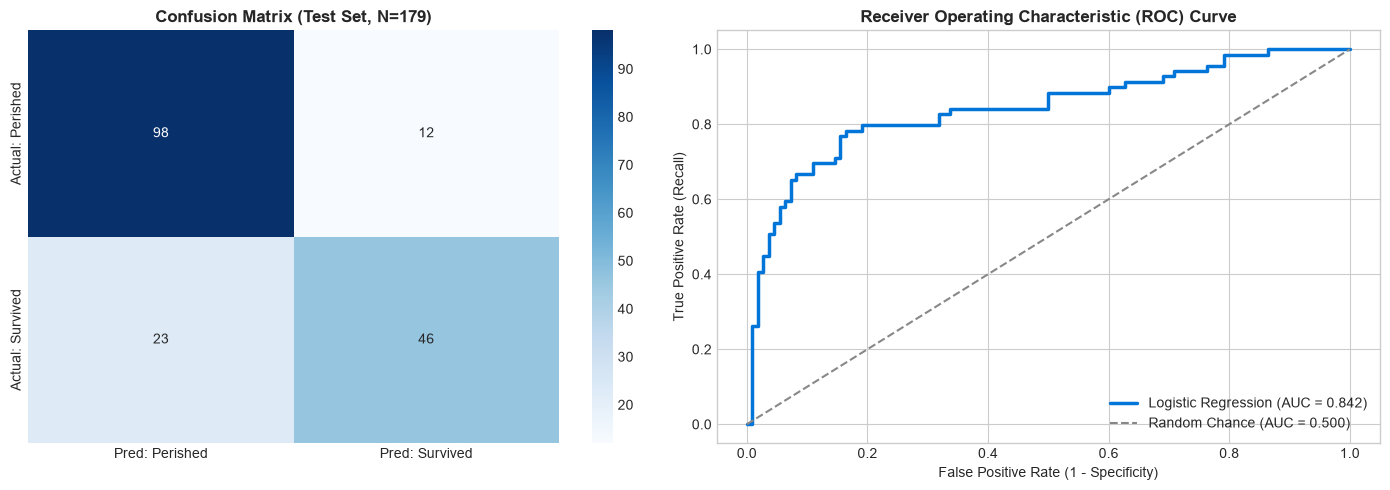

In [13]:
# Plotting Confusion Matrix and ROC Curve side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Pred: Perished', 'Pred: Survived'],
            yticklabels=['Actual: Perished', 'Actual: Survived'])
axes[0].set_title('Confusion Matrix (Test Set, N=179)', fontsize=12, fontweight='bold')

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
auc_val = roc_auc_score(y_test, y_pred_proba)
axes[1].plot(fpr, tpr, color='#0275d8', lw=2.5, label=f'Logistic Regression (AUC = {auc_val:.3f})')
axes[1].plot([0, 1], [0, 1], color='#888888', lw=1.5, linestyle='--', label='Random Chance (AUC = 0.500)')
axes[1].set_xlabel('False Positive Rate (1 - Specificity)')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=12, fontweight='bold')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

**Student Interpretation of Model Performance:**
- **Accuracy of 80.45%:** The model correctly predicts 8 out of 10 passengers on test data.
- **Precision of 79.31%:** When the model says someone survived, it is correct nearly 80% of the time.
- **Recall of 66.67%:** Out of the 69 actual survivors in the test set, the model successfully caught 46 of them.
- **ROC-AUC of 0.842:** This high AUC score proves the model has strong discriminative capability across different decision thresholds.

## Step 7: Model Interpretation & Odds Ratios ($e^\beta$)

In Logistic Regression, the raw coefficients represent changes in the **log-odds**:
$$\ln\left(\frac{P}{1-P}\right) = \beta_0 + \sum_{i=1}^k \beta_i X_i$$

By exponentiating the coefficient ($\text{Odds Ratio} = e^{\beta}$), we can interpret the effect on the actual **odds of survival**:
- $\text{OR} > 1$: Increases odds of survival.
- $\text{OR} < 1$: Decreases odds of survival.
- Percentage Change in Odds $= (e^{\beta} - 1) \times 100\%$.

In [14]:
# Extract feature names from preprocessor
ohe_cat_features = model_pipeline.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(categorical_features)
feature_names = numeric_features + list(ohe_cat_features)
coefs = model_pipeline.named_steps['classifier'].coef_[0]
intercept = model_pipeline.named_steps['classifier'].intercept_[0]

odds_ratios = np.exp(coefs)
pct_change = (odds_ratios - 1) * 100

coef_table = pd.DataFrame({
    'Feature': feature_names,
    'Log-Odds (Beta)': coefs,
    'Odds Ratio (e^Beta)': odds_ratios,
    '% Change in Odds': pct_change
}).sort_values(by='Log-Odds (Beta)', ascending=False).reset_index(drop=True)

print(f"Model Intercept: {intercept:.4f} (Base Odds: {np.exp(intercept):.4f})")
coef_table.round(4)

Model Intercept: 2.5710 (Base Odds: 13.0793)


,Feature,Log-Odds (Beta),Odds Ratio (e^Beta),% Change in Odds
0,Embarked_Q,0.1754,1.1917,19.1735
1,Fare,0.1668,1.1815,18.1503
2,Parch,-0.0677,0.9345,-6.5464
3,SibSp,-0.2802,0.7557,-24.4343
4,Embarked_S,-0.3973,0.6722,-32.7844
5,Age,-0.5291,0.5891,-41.0867
6,Pclass_2,-0.8423,0.4307,-56.9303
7,Pclass_3,-2.0828,0.1246,-87.5423
8,Sex_male,-2.5095,0.0813,-91.8689


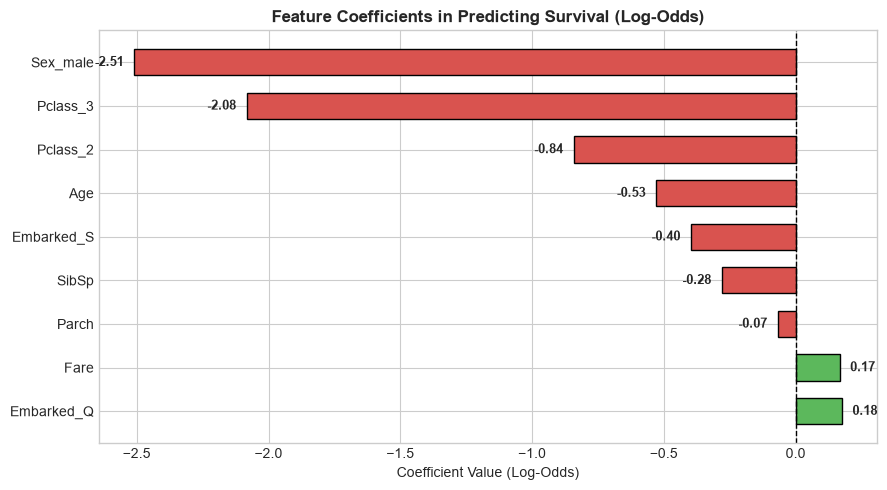

In [15]:
# Bar chart of feature impact
plt.figure(figsize=(9, 5))
colors = ['#5cb85c' if c > 0 else '#d9534f' for c in coef_table['Log-Odds (Beta)']]
bars = plt.barh(coef_table['Feature'], coef_table['Log-Odds (Beta)'], color=colors, edgecolor='black', height=0.6)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.title('Feature Coefficients in Predicting Survival (Log-Odds)', fontsize=12, fontweight='bold')
plt.xlabel('Coefficient Value (Log-Odds)')

for bar in bars:
    w = bar.get_width()
    plt.text(w + (0.04 if w > 0 else -0.04), bar.get_y() + bar.get_height()/2, f"{w:.2f}",
             va='center', ha='left' if w > 0 else 'right', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

### Detailed Interpretation of Findings:
1. **`Sex_male` ($\beta = -2.51$, Odds Ratio $= 0.081$):**
   Being male is by far the biggest negative factor. Holding other variables constant, male passengers had a **91.87% lower odds of survival** compared to females. This directly reflects the captain's evacuation order.
2. **`Pclass_3` ($\beta = -2.08$, Odds Ratio $= 0.125$) and `Pclass_2` ($\beta = -0.84$, Odds Ratio $= 0.431$):**
   Relative to 1st class passengers, 3rd class passengers experienced an **87.54% reduction** in survival odds, and 2nd class experienced a **56.93% reduction**. This confirms that cabin location and class priority heavily determined who got to the lifeboats.
3. **`Age` ($\beta = -0.53$, Odds Ratio $= 0.589$ per std dev):**
   Each standard deviation increase in age (~14 years) reduced survival odds by **41.09%**, confirming children were prioritized over older adults.
4. **`Fare` ($\beta = +0.17$, Odds Ratio $= 1.182$ per std dev):**
   Higher ticket prices increased the odds of survival by **18.15%** per standard deviation.

## Step 8: Streamlit Web Deployment (`app.py`)

To satisfy the deployment task, I built an interactive web app using **Streamlit**.

### How to run the web app:
```bash
streamlit run app.py
```

### App Features:
- **Live Survival Prediction:** Sliders and inputs for Passenger Class, Age, Gender, Fare, and Embarkation port.
- **Preset Characters:** Try famous characters like Rose (1st Class Female) or Jack (3rd Class Male).
- **Visual Probability Breakdown:** Live progress bar showing Survival % vs Mortality %.
- **Model Insights & EDA Dashboard:** Tabbed view of all our graphs, confusion matrix, and coefficients.